# Retail Revenue & Customer Behaviour Analysis 

## Project Overview

This project explores online retail transactions to understand revenue trends, product performance, country-wise sales, and customer purchasing patterns using Python.

In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
file_path = "../data/online_retail_II.xlsx"

df_2009_2010 = pd.read_excel(file_path, sheet_name="Year 2009-2010")
df_2010_2011 = pd.read_excel(file_path, sheet_name="Year 2010-2011")

In [4]:
df_2009_2010.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom


In [5]:
df_2010_2011.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536368,22960,JAM MAKING SET WITH JARS,6,2010-12-01 08:34:00,4.25,13047.0,United Kingdom


In [6]:
df = pd.concat(
    [df_2009_2010, df_2010_2011],
    ignore_index=True
)

In [7]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [8]:
df.shape

(1067371, 8)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [10]:
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')

In [11]:
df.dtypes

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object

In [12]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [13]:
df[df["Customer ID"].isnull()].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom


In [14]:
df["Customer ID"].isnull().sum()

np.int64(243007)

In [15]:
df[df["Description"].isnull()].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom


In [16]:
df["Description"].isnull().sum()

np.int64(4382)

In [17]:
df["Country"].unique()

array(['United Kingdom', 'France', 'USA', 'Belgium', 'Australia', 'EIRE',
       'Germany', 'Portugal', 'Japan', 'Denmark', 'Nigeria',
       'Netherlands', 'Poland', 'Spain', 'Channel Islands', 'Italy',
       'Cyprus', 'Greece', 'Norway', 'Austria', 'Sweden',
       'United Arab Emirates', 'Finland', 'Switzerland', 'Unspecified',
       'Malta', 'Bahrain', 'RSA', 'Bermuda', 'Hong Kong', 'Singapore',
       'Thailand', 'Israel', 'Lithuania', 'West Indies', 'Lebanon',
       'Korea', 'Brazil', 'Canada', 'Iceland', 'Saudi Arabia',
       'Czech Republic', 'European Community'], dtype=object)

In [18]:
df["Country"].nunique()

43

In [19]:
df.duplicated().sum()

np.int64(34335)

In [20]:
df.count().duplicated()

Invoice        False
StockCode       True
Description    False
Quantity        True
InvoiceDate     True
Price           True
Customer ID    False
Country         True
dtype: bool

In [21]:
df[df.duplicated()]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067136,581538,22068,BLACK PIRATE TREASURE CHEST,1,2011-12-09 11:34:00,0.39,14446.0,United Kingdom
1067150,581538,23318,BOX OF 6 MINI VINTAGE CRACKERS,1,2011-12-09 11:34:00,2.49,14446.0,United Kingdom
1067153,581538,22992,REVOLVER WOODEN RULER,1,2011-12-09 11:34:00,1.95,14446.0,United Kingdom
1067160,581538,22694,WICKER STAR,1,2011-12-09 11:34:00,2.10,14446.0,United Kingdom


In [22]:
df[df.duplicated()].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
390,489517,84951A,S/4 PISTACHIO LOVEBIRD COASTERS,1,2009-12-01 11:34:00,2.55,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
657,489529,22028,PENNY FARTHING BIRTHDAY CARD,12,2009-12-01 11:51:00,0.42,17984.0,United Kingdom
658,489529,22036,DINOSAUR BIRTHDAY CARD,12,2009-12-01 11:51:00,0.42,17984.0,United Kingdom


In [23]:
df[df.duplicated(keep=False)].head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


In [24]:
df.shape

(1067371, 8)

In [25]:
df.drop_duplicates().shape

(1033036, 8)

In [26]:
df["InvoiceDate"].head(10)

0   2009-12-01 07:45:00
1   2009-12-01 07:45:00
2   2009-12-01 07:45:00
3   2009-12-01 07:45:00
4   2009-12-01 07:45:00
5   2009-12-01 07:45:00
6   2009-12-01 07:45:00
7   2009-12-01 07:45:00
8   2009-12-01 07:46:00
9   2009-12-01 07:46:00
Name: InvoiceDate, dtype: datetime64[ns]

In [27]:
df["InvoiceDate"].max()

Timestamp('2011-12-09 12:50:00')

In [28]:
df["InvoiceDate"].tail(10)

1067361   2011-12-09 12:50:00
1067362   2011-12-09 12:50:00
1067363   2011-12-09 12:50:00
1067364   2011-12-09 12:50:00
1067365   2011-12-09 12:50:00
1067366   2011-12-09 12:50:00
1067367   2011-12-09 12:50:00
1067368   2011-12-09 12:50:00
1067369   2011-12-09 12:50:00
1067370   2011-12-09 12:50:00
Name: InvoiceDate, dtype: datetime64[ns]

In [29]:
df["InvoiceDate"].min()

Timestamp('2009-12-01 07:45:00')

In [30]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [31]:
df["Invoice"].nunique()

53628

In [32]:
df["Customer ID"].count()

np.int64(824364)

In [33]:
df["Customer ID"].nunique()

5942

In [34]:
df[["Quantity", "Price"]].agg(["min", "max"])

,Quantity,Price
min,-80995,-53594.36
max,80995,38970.00


In [35]:
df[df.duplicated(keep=False)].sort_values(
    ["Invoice", "StockCode", "Customer ID"]
).head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom


In [36]:
df.duplicated(keep=False)

0          False
1          False
2          False
3          False
4          False
           ...  
1067366    False
1067367    False
1067368    False
1067369    False
1067370    False
Length: 1067371, dtype: bool

In [37]:
df.duplicated().sum()

np.int64(34335)

In [38]:
df.drop_duplicates().shape

(1033036, 8)

In [39]:
df[df["Quantity"]< 0].head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [40]:
df[df["Quantity"]< 0].count()

Invoice        22950
StockCode      22950
Description    20261
Quantity       22950
InvoiceDate    22950
Price          22950
Customer ID    18744
Country        22950
dtype: int64

In [41]:
df[df["Quantity"]< 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
...,...,...,...,...,...,...,...,...
1065910,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397.0,United Kingdom
1067002,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.0,United Kingdom
1067176,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311.0,United Kingdom
1067177,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315.0,United Kingdom


In [42]:
df[df["Price"]< 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [43]:
df[df["Description"].isnull()]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
1060783,581199,84581,NaN,-2,2011-12-07 18:26:00,0.0,NaN,United Kingdom
1060787,581203,23406,NaN,15,2011-12-07 18:31:00,0.0,NaN,United Kingdom
1060793,581209,21620,NaN,6,2011-12-07 18:35:00,0.0,NaN,United Kingdom
1062442,581234,72817,NaN,27,2011-12-08 10:33:00,0.0,NaN,United Kingdom


In [44]:
df[df["Description"].isnull()]["Customer ID"].isnull().sum()

np.int64(4382)

In [45]:
df[df["Description"].isnull()]["StockCode"].value_counts().head(20)

StockCode
84990     12
22139     12
35965     11
79321     11
22950     10
23084     10
22084      9
22087      9
71477      8
37461      8
35970      7
72803B     7
84795D     7
84977      7
37509      7
22528      7
21768      7
22451      7
POST       7
22467      6
Name: count, dtype: int64

In [46]:
df.loc[df["Description"].isnull(), "StockCode"].head(10)

470      21646
3114     20683
3161     21350
3731     84292
4296     18010
4566    85049G
6378    35751C
6555    79323G
6576     21098
6581     21166
Name: StockCode, dtype: object

In [47]:
df.loc[df["StockCode"] == "35751C", "Description"].value_counts(dropna=False).head(10)

Description
PURPLE CURRENT CANDLE RING    2
NaN                           1
Name: count, dtype: int64

In [48]:
df_clean = df.drop_duplicates().copy()
df_clean.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [49]:
df_clean.shape

(1033036, 8)

In [50]:
df_clean.isnull().sum()

Invoice             0
StockCode           0
Description      4275
Quantity            0
InvoiceDate         0
Price               0
Customer ID    235151
Country             0
dtype: int64

In [51]:
df_clean[df_clean["Description"].isnull()]["Customer ID"].isnull().sum()

np.int64(4275)

In [52]:
df_clean.loc[df_clean["StockCode"] == "35751C", "Description"].value_counts(dropna=False).head(10)

Description
PURPLE CURRENT CANDLE RING    2
NaN                           1
Name: count, dtype: int64

In [53]:
df_clean[df_clean["StockCode"] == "35751C"]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
440,489520,35751C,PURPLE CURRENT CANDLE RING,12,2009-12-01 11:41:00,0.75,14911.0,EIRE
6378,489882,35751C,NaN,12,2009-12-02 16:22:00,0.00,NaN,United Kingdom
6385,489884,35751C,PURPLE CURRENT CANDLE RING,19,2009-12-02 16:24:00,0.19,13313.0,United Kingdom


In [54]:
df_clean["Customer ID"].isnull().sum()

np.int64(235151)

In [55]:
df_clean["Description"].isnull().sum()

np.int64(4275)

In [56]:
df_clean["StockCode"].isnull().sum()

np.int64(0)

In [57]:
df_clean[df_clean["Quantity"] < 0].count()

Invoice        22496
StockCode      22496
Description    19863
Quantity       22496
InvoiceDate    22496
Price          22496
Customer ID    18390
Country        22496
dtype: int64

In [58]:
df_clean[df_clean["Price"] < 0].count()

Invoice        5
StockCode      5
Description    5
Quantity       5
InvoiceDate    5
Price          5
Customer ID    0
Country        5
dtype: int64

In [59]:
df_clean = df_clean[(df_clean["Quantity"] > 0) & (df_clean["Price"] > 0)].copy()

In [60]:
df_clean[df_clean["Price"] < 0].count()

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64

In [61]:
df_clean[df_clean["Quantity"] < 0].count()

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64

In [62]:
df_customers = df_clean.dropna(subset=["Customer ID"])

In [63]:
df_customers.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [64]:
df_clean.isnull().sum()

Invoice             0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
Price               0
Customer ID    228489
Country             0
dtype: int64

In [65]:
df_clean.shape

(1007914, 8)

In [66]:
df_clean.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [67]:
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["Price"]

In [68]:
df_clean["Revenue"]

0           83.40
1           81.00
2           81.00
3          100.80
4           30.00
            ...  
1067366     12.60
1067367     16.60
1067368     16.60
1067369     14.85
1067370     18.00
Name: Revenue, Length: 1007914, dtype: float64

In [69]:
df_clean.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [70]:
df_clean["Revenue"].describe()

count    1.007914e+06
mean     2.031585e+01
std      2.057160e+02
min      1.000000e-03
25%      4.130000e+00
50%      1.008000e+01
75%      1.770000e+01
max      1.684696e+05
Name: Revenue, dtype: float64

In [71]:
df_clean["Revenue"].lt(0).sum()

np.int64(0)

In [72]:
df_clean["Revenue"].gt(0).sum()

np.int64(1007914)

In [73]:
df_clean["Revenue"].eq(0).sum()

np.int64(0)

In [74]:
df_clean["Revenue"].sum()

np.float64(20476634.018)

In [75]:
df_clean.loc[df_clean["Revenue"] > 0, "Revenue"].sum()

np.float64(20476634.018)

In [76]:
df_clean[df_clean["Invoice"].astype(str).str.startswith("C")].shape[0]

1

In [77]:
df_clean.loc[df_clean["Revenue"] < 0, "Revenue"].sum()

np.float64(0.0)

In [78]:
df_clean.loc[df_clean["Invoice"].astype(str).str.startswith("C"), "Revenue"].sum()

np.float64(373.57)

In [79]:
df_clean.loc[df_clean["Invoice"].astype(str).str.startswith("C"), "Invoice"].nunique()

1

In [80]:
df_clean.loc[df_clean["Invoice"].astype(str).str.startswith("C")]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
76799,C496350,M,Manual,1,2010-02-01 08:24:00,373.57,NaN,United Kingdom,373.57


In [81]:
df_clean = df_clean[~df_clean["Invoice"].astype(str).str.startswith("C")].copy()

In [82]:
df["Invoice"].astype(str).str.startswith("C").sum()

np.int64(19494)

In [83]:
Country_revenue = df_clean.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
Country_revenue

Country
United Kingdom          1.741020e+07
EIRE                    6.587673e+05
Netherlands             5.540381e+05
Germany                 4.250197e+05
France                  3.504561e+05
Australia               1.692835e+05
Spain                   1.083325e+05
Switzerland             1.006856e+05
Sweden                  9.186982e+04
Denmark                 6.858069e+04
Belgium                 6.538782e+04
Norway                  5.632250e+04
Portugal                5.628353e+04
Channel Islands         4.462333e+04
Japan                   4.302391e+04
Italy                   3.210817e+04
Finland                 2.992554e+04
Singapore               2.531706e+04
Cyprus                  2.484995e+04
Hong Kong               2.368552e+04
Austria                 2.361301e+04
Greece                  1.909619e+04
Israel                  1.132881e+04
United Arab Emirates    1.109763e+04
Unspecified             1.092716e+04
Poland                  1.065429e+04
USA                     8.3668

In [84]:
Description_revenue = df_clean.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(20)
Description_revenue 

Description
Manual                                 339241.29
REGENCY CAKESTAND 3 TIER               330590.32
DOTCOM POSTAGE                         309854.11
WHITE HANGING HEART T-LIGHT HOLDER     260990.22
PAPER CRAFT , LITTLE BIRDIE            168469.60
PARTY BUNTING                          148318.28
JUMBO BAG RED RETROSPOT                148073.47
ASSORTED COLOUR BIRD ORNAMENT          129324.49
POSTAGE                                125682.42
PAPER CHAIN KIT 50'S CHRISTMAS         117760.29
MEDIUM CERAMIC TOP STORAGE JAR          81700.92
CHILLI LIGHTS                           80540.88
ROTATING SILVER ANGELS T-LIGHT HLDR     71300.40
JUMBO BAG STRAWBERRY                    69002.13
RABBIT NIGHT LIGHT                      66870.03
BLACK RECORD COVER FRAME                65189.29
JUMBO STORAGE BAG SUKI                  61537.55
VINTAGE UNION JACK BUNTING              60286.04
EDWARDIAN PARASOL NATURAL               60145.85
HOT WATER BOTTLE TEA AND SYMPATHY       59189.14
Name: Re

In [85]:
df_clean.groupby("Quantity")["Revenue"].sum().sort_values(ascending=False).head(10)

Quantity
12    2243102.640
1     2046223.448
6     1402370.220
2     1374311.360
24    1367526.000
4     1061237.160
10     815091.200
3      754275.090
48     698348.160
8      546142.720
Name: Revenue, dtype: float64

In [86]:
df_clean.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     106139
WHITE HANGING HEART T-LIGHT HOLDER     94658
PAPER CRAFT , LITTLE BIRDIE            80995
ASSORTED COLOUR BIRD ORNAMENT          80082
MEDIUM CERAMIC TOP STORAGE JAR         78033
JUMBO BAG RED RETROSPOT                77699
BROCADE RING PURSE                     70369
PACK OF 60 PINK PAISLEY CAKE CASES     56061
60 TEATIME FAIRY CAKE CASES            54028
SMALL POPCORN HOLDER                   48561
Name: Quantity, dtype: int64

In [87]:
df_clean["Month"] = df_clean["InvoiceDate"].dt.to_period("M")

In [88]:
df_clean.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Month
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0,2009-12


In [89]:
df_clean.groupby("Month")["Revenue"].sum().sort_values(ascending=False).head(10)

Month
2011-11    1503866.780
2010-11    1464293.142
2010-10    1161902.220
2011-10    1151263.730
2011-09    1056435.192
2010-09     921696.991
2010-03     830915.261
2009-12     822483.950
2010-12     821452.730
2011-05     769296.610
Freq: M, Name: Revenue, dtype: float64

In [90]:
monthly_revenue = df_clean.groupby("Month")["Revenue"].sum().sort_index()
monthly_revenue

Month
2009-12     822483.950
2010-01     651155.112
2010-02     551504.726
2010-03     830915.261
2010-04     678875.252
2010-05     657705.500
2010-06     749537.310
2010-07     648810.270
2010-08     695251.910
2010-09     921696.991
2010-10    1161902.220
2010-11    1464293.142
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637808.330
Freq: M, Name: Revenue, dtype: float64

In [91]:
Changed_Revenue = monthly_revenue.diff()
Changed_Revenue

Month
2009-12           NaN
2010-01   -171328.838
2010-02    -99650.386
2010-03    279410.535
2010-04   -152040.009
2010-05    -21169.752
2010-06     91831.810
2010-07   -100727.040
2010-08     46441.640
2010-09    226445.081
2010-10    240205.229
2010-11    302390.922
2010-12   -642840.412
2011-01   -131641.120
2011-02   -167266.050
2011-03    193669.700
2011-04   -179246.769
2011-05    232328.119
2011-06     -8749.600
2011-07    -42470.889
2011-08     39765.259
2011-09    298593.812
2011-10     94828.538
2011-11    352603.050
2011-12   -866058.450
Freq: M, Name: Revenue, dtype: float64

In [92]:
Revenue_Growth = monthly_revenue.pct_change() * 100
Revenue_Growth

Month
2009-12          NaN
2010-01   -20.830660
2010-02   -15.303633
2010-03    50.663307
2010-04   -18.297896
2010-05    -3.118357
2010-06    13.962451
2010-07   -13.438563
2010-08     7.157969
2010-09    32.570221
2010-10    26.061193
2010-11    26.025505
2010-12   -43.901074
2011-01   -16.025404
2011-02   -24.248077
2011-03    37.062740
2011-04   -25.026941
2011-05    43.266620
2011-06    -1.137351
2011-07    -5.584256
2011-08     5.537750
2011-09    39.400568
2011-10     8.976276
2011-11    30.627478
2011-12   -57.588775
Freq: M, Name: Revenue, dtype: float64

In [93]:
df_customers["Revenue"] = df_customers["Quantity"] * df_customers["Price"]

In [94]:
Customer_revenue= df_customers.groupby("Customer ID")["Revenue"].sum().sort_values(ascending=False).head(10)
Customer_revenue

Customer ID
18102.0    580987.04
14646.0    528602.52
14156.0    313437.62
14911.0    291420.81
17450.0    244784.25
13694.0    195640.69
17511.0    172132.87
16446.0    168472.50
16684.0    147142.77
12415.0    144458.37
Name: Revenue, dtype: float64

## Univariate analysis

### Revenue distribution

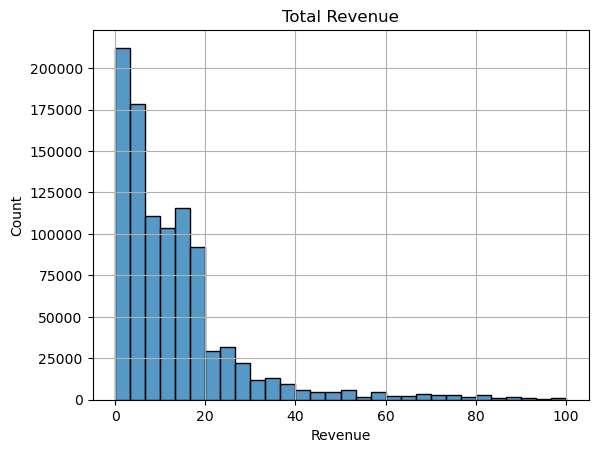

In [95]:
sns.histplot(df_clean.loc[df_clean["Revenue"].between(-100,100), "Revenue"], bins=30)
plt.title("Total Revenue")
plt.xlabel("Revenue")
plt.ylabel("Count")
plt.grid()
plt.savefig(
    "../images/revenue_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

### Quantity Distribution

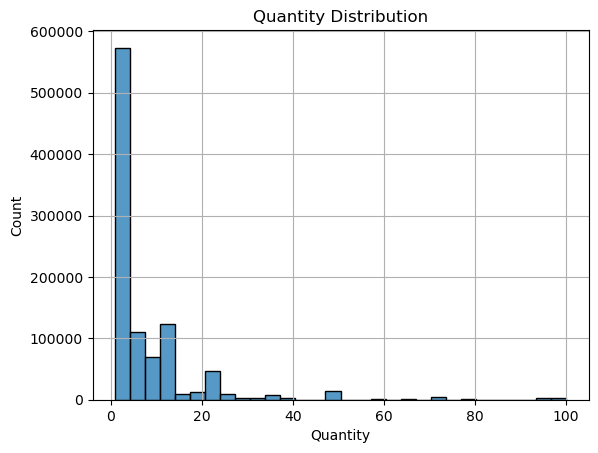

In [96]:
sns.histplot(df_clean.loc[df_clean["Quantity"].between(0, 100), "Quantity"], bins=30)
plt.title("Quantity Distribution")
plt.xlabel("Quantity")
plt.ylabel("Count")
plt.grid()
plt.savefig(
    "../images/quantity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

### Unit price distribution

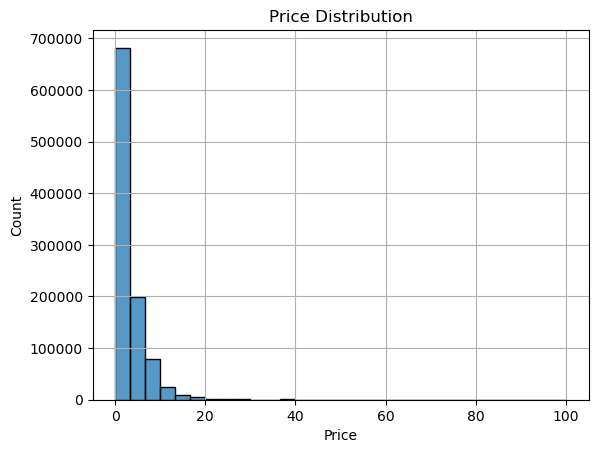

In [97]:
sns.histplot(df_clean.loc[df_clean["Price"].between(0, 100), "Price"], bins=30)
plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Count")
plt.grid()
plt.savefig(
    "../images/price_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

### Top countries by transaction count

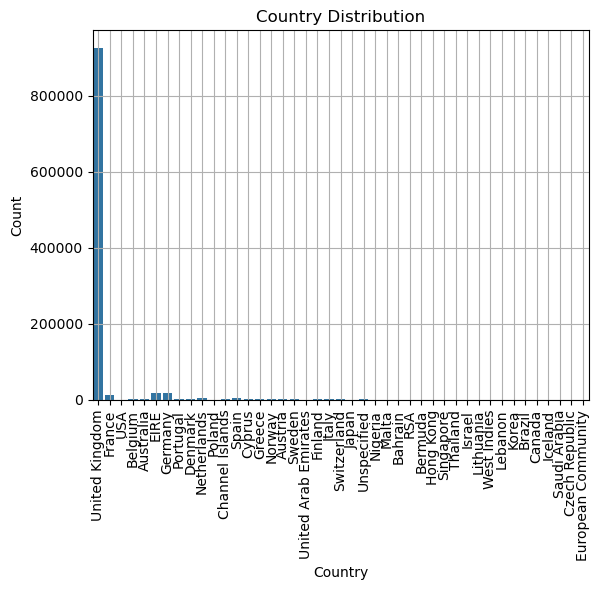

In [98]:
sns.countplot(x = df_clean["Country"])
plt.title("Country Distribution")
plt.xlabel("Country")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.grid()
plt.savefig(
    "../images/top_countries_by_transaction_count.png",
    dpi=300,
    bbox_inches="tight"
)


## Bivariate analysis

### Quantity By Price

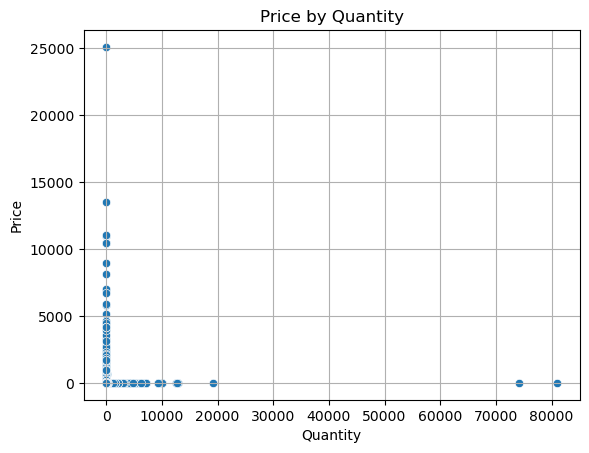

In [99]:
sns.scatterplot(x = df_clean["Quantity"], y = df_clean["Price"])
plt.title("Price by Quantity")
plt.xlabel("Quantity")
plt.ylabel("Price")
plt.grid()
plt.savefig(
    "../images/quantity_by_price.png",
    dpi=300,
    bbox_inches="tight"
)

### Country vs revenue

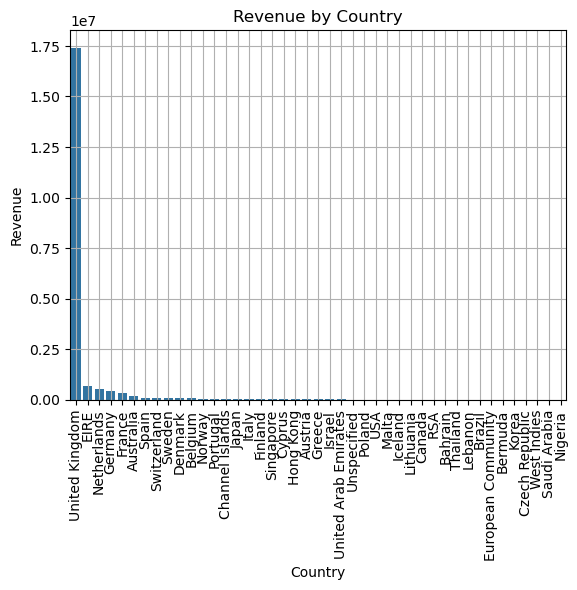

In [100]:
sns.barplot(x=Country_revenue.index, y=Country_revenue.values)
plt.title("Revenue by Country")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=90)
plt.grid()
plt.savefig(
    "../images/country_vs_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

### Product vs revenue

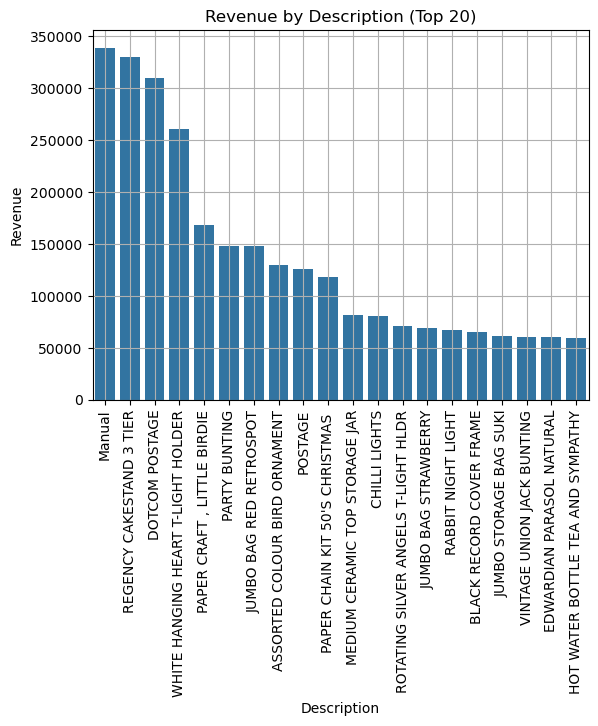

In [101]:
sns.barplot(x = Description_revenue.index, y = Description_revenue.values)
plt.title("Revenue by Description (Top 20)")
plt.xlabel("Description")
plt.ylabel("Revenue")
plt.xticks(rotation=90)
plt.grid()
plt.savefig(
    "../images/product_vs_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

### Month vs revenue

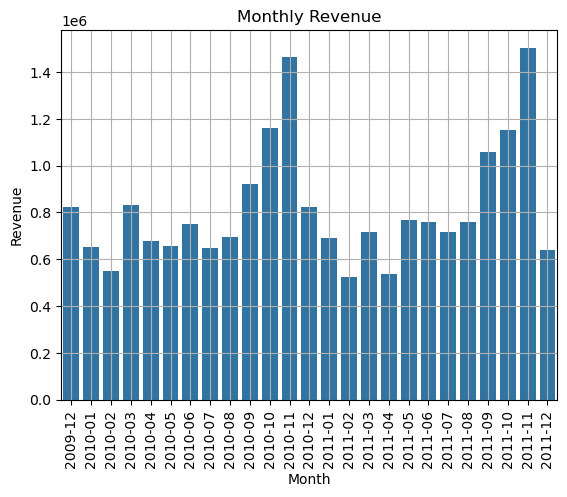

In [102]:
sns.barplot(x = monthly_revenue.index, y = monthly_revenue.values)
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.xticks(rotation=90)
plt.ylabel("Revenue")
plt.grid()
plt.savefig(
    "../images/month_vs_revenue.png",
    dpi=300,
    bbox_inches="tight"
)


### Top 10 Customers by Revenue

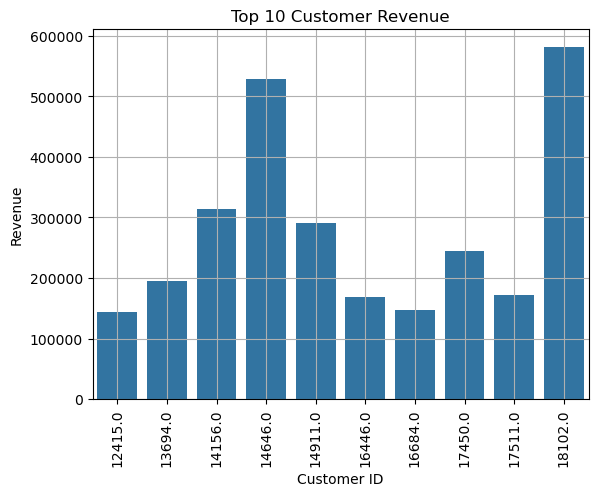

In [103]:
sns.barplot(x = Customer_revenue.index, y = Customer_revenue.values)
plt.title("Top 10 Customer Revenue")
plt.xlabel("Customer ID")
plt.xticks(rotation=90)
plt.ylabel("Revenue")
plt.grid()
plt.savefig(
    "../images/top_10_customers_by_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

## Qutliers

### Quantity

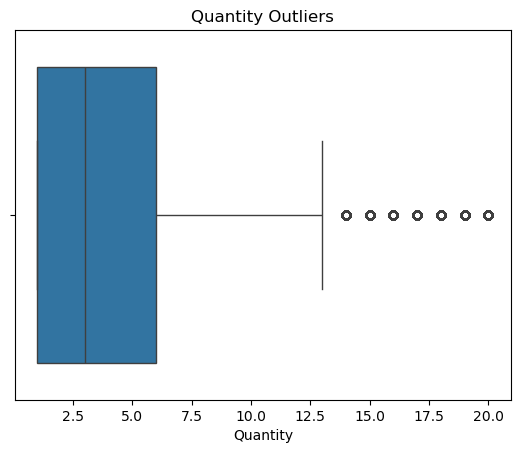

In [104]:
sns.boxplot(x = df_clean.loc[df_clean["Quantity"].between(-20, 20), "Quantity"])
plt.title("Quantity Outliers")
plt.xlabel("Quantity")
plt.savefig(
    "../images/quantity_outliers.png",
    dpi=300,
    bbox_inches="tight"
)

In [105]:
Minimum, Q1, Median, Q3, Maximum = np.quantile(df_clean["Quantity"], [0, 0.25, 0.50, 0.75, 1.0])
print("Minimum:", Minimum)
print("Q1:", Q1)
print("Median:", Median)
print("Q3:", Q3)
print("Maximum:", Maximum)

Minimum: 1.0
Q1: 1.0
Median: 4.0
Q3: 12.0
Maximum: 80995.0


In [106]:
IQR = Q3 - Q1
IQR

np.float64(11.0)

In [107]:
Lower_limit = Q1 - 1.5 * IQR
Lower_limit

np.float64(-15.5)

In [108]:
Upper_limit = Q3 + 1.5 * IQR
Upper_limit

np.float64(28.5)

In [109]:
Quantity_Outliers = df_clean[
    (df_clean["Quantity"] < Lower_limit) |
    (df_clean["Quantity"] > Upper_limit)
]

print("Lower Limit:", Lower_limit)
print("Upper Limit:", Upper_limit)
print("Number of Outliers:", len(Quantity_Outliers))

Lower Limit: -15.5
Upper Limit: 28.5
Number of Outliers: 53061


### Unit Price

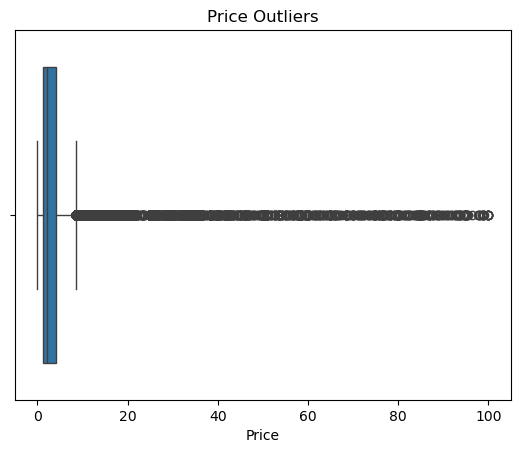

In [110]:
sns.boxplot(x = df_clean.loc[df_clean["Price"].between(-100, 100), "Price"])
plt.title("Price Outliers")
plt.xlabel("Price")
plt.savefig(
    "../images/price_outliers.png",
    dpi=300,
    bbox_inches="tight"
)

In [111]:
Minimum, Q1, Median, Q3, Maximum = np.quantile(df_clean["Price"], [0, 0.25, 0.50, 0.75, 1.0])
print("Minimum:", Minimum)
print("Q1:", Q1)
print("Median:", Median)
print("Q3:", Q3)
print("Maximum:", Maximum)

Minimum: 0.001
Q1: 1.25
Median: 2.1
Q3: 4.13
Maximum: 25111.09


In [112]:
IQR = Q3 - Q1
IQR

np.float64(2.88)

In [113]:
Lower_limit = Q1 - 1.5 * IQR
Lower_limit

np.float64(-3.0700000000000003)

In [114]:
Upper_limit = Q3 + 1.5 * IQR
Upper_limit

np.float64(8.45)

In [115]:
Price_Outliers = df_clean[
    (df_clean["Price"] < Lower_limit) |
    (df_clean["Price"] > Upper_limit)
]

print("Lower Limit:", Lower_limit)
print("Upper Limit:", Upper_limit)
print("Number of Outliers:", len(Price_Outliers))

Lower Limit: -3.0700000000000003
Upper Limit: 8.45
Number of Outliers: 78999


In [116]:
df_clean["Price"].sort_values(ascending=False).head(10)

241827    25111.09
517955    13541.33
825443    11062.06
135015    10953.50
135013    10953.50
372834    10468.80
342147    10468.80
358639    10468.80
74356      8985.60
698843     8142.75
Name: Price, dtype: float64

In [117]:
df_clean["Price"].sort_values().head(10) 

104480    0.001
341826    0.001
468280    0.001
97716     0.001
62299     0.001
178629    0.001
123947    0.001
887202    0.001
682656    0.001
101718    0.001
Name: Price, dtype: float64

In [118]:
df_clean.loc[
    (df_clean["Price"] > 0) &
    (df_clean["Price"] < 1000),
    ["Invoice", "StockCode", "Description",
     "Quantity", "Price", "Revenue", "Country"]
].sort_values("Price").head(20)

,Invoice,StockCode,Description,Quantity,Price,Revenue,Country
341826,522766,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001,United Kingdom
79794,496643,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001,United Kingdom
77702,496473,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001,United Kingdom
804506,561226,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001,United Kingdom
62299,494914,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001,United Kingdom
885332,568200,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001,United Kingdom
156809,504332,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001,Germany
178629,506303,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001,United Kingdom
104480,499399,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001,United Kingdom
90798,497935,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001,United Kingdom


In [119]:
df_clean["Price"].describe()

count    1.007913e+06
mean     4.074252e+00
std      5.043045e+01
min      1.000000e-03
25%      1.250000e+00
50%      2.100000e+00
75%      4.130000e+00
max      2.511109e+04
Name: Price, dtype: float64

# RFM Customer Segmentation

In [120]:
df_customers["InvoiceDate"] = pd.to_datetime(df_customers["InvoiceDate"])

In [121]:
snapshot_date = df_customers["InvoiceDate"].max() + pd.Timedelta(days=1)

In [122]:
rfm = df_customers.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

In [123]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5, labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

In [124]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)


In [125]:
def segment_customer(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"
    elif row["R_Score"] >= 3 and row["F_Score"] >= 4:
        return "Loyal Customers"
    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"
    else:
        return "Others"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)


In [126]:
rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346.0,326,12,77556.46,2,5,5,255,At Risk
1,12347.0,2,8,4921.53,5,4,5,545,Champions
2,12348.0,75,5,2019.40,3,4,4,344,Loyal Customers
3,12349.0,19,4,4428.69,5,3,5,535,Others
4,12350.0,310,1,334.40,2,1,2,212,Others


# Customer count and revenue by segment

In [127]:
segment_summary = rfm.groupby("Segment").agg(
    Customer_Count=("Customer ID", "count"),
    Total_Revenue=("Monetary", "sum"),
    Average_Customer_Value=("Monetary", "mean")
).reset_index()

segment_summary["Revenue_Share_%"] = (
    segment_summary["Total_Revenue"] /
    segment_summary["Total_Revenue"].sum() * 100
).round(2)

segment_summary = segment_summary.sort_values(
    "Total_Revenue", ascending=False
)

segment_summary

,Segment,Customer_Count,Total_Revenue,Average_Customer_Value,Revenue_Share_%
1,Champions,1289,1.181963e+07,9169.609678,68.03
3,Others,3056,2.069161e+06,677.081622,11.91
2,Loyal Customers,708,1.895631e+06,2677.445445,10.91
0,At Risk,825,1.590385e+06,1927.738887,9.15


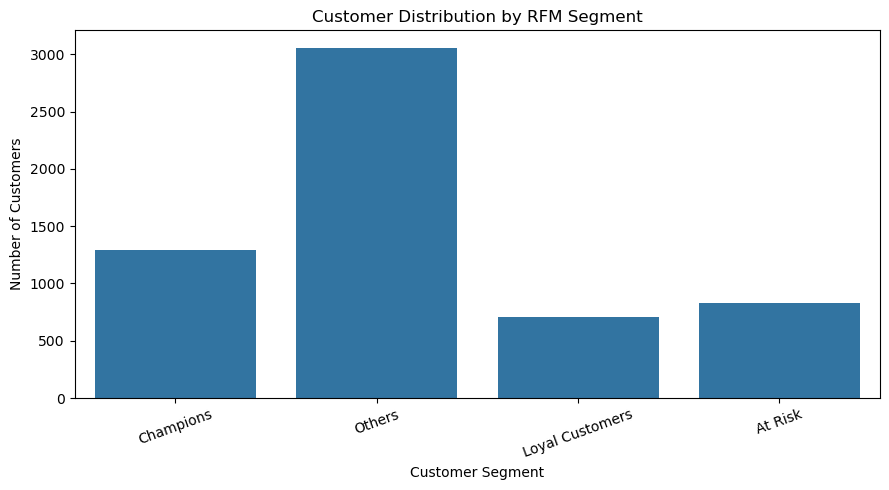

In [128]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=segment_summary,
    x="Segment",
    y="Customer_Count"
)

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(
    "../images/Customer_Distribution_by_RFM_Segment.png",
    bbox_inches="tight"
)
plt.show()